# 05 · Selección del modelo, prueba única y registro

1. **Champion y challenger**: las dos mejores familias por PR-AUC por evento en la CV (versiones optimizadas del
   notebook 04 y candidatos del 03), con la pregunta de si la diferencia supera la variación entre pliegues.
2. **Modelos finales**: se entrenan con **todo** el período de entrenamiento (2018-01 → 2019-09) con el mismo protocolo
   (todas las fallas + 15 % de los discos sanos, semilla 42).
3. **Prueba única en noviembre de 2019** (después de un mes de embargo), con todas sus filas: PR-AUC y F0,5 por
   evento, discos vistos y no vistos en entrenamiento, anticipación. **Esta es la única vez que se usa la prueba.**
4. **Métrica de negocio**: costo esperado por 1.000 SSD-mes con C_FP = 1 y C_FN = k, k ∈ [1, 50], frente a la regla
   de umbral; k de equilibrio. Los modelos se comparan **al mismo presupuesto de alertas** (compromiso del PSet #1): en
   la CV (predicciones out-of-fold) se elige cuántas alertas por 1.000 SSD-mes conviene emitir, y en la prueba cada
   modelo emite esa cantidad con sus scores más altos. El umbral de la prueba se busca **sin etiquetas** (contar
   alertas solo requiere disco, fecha y score), así que no hay fuga; y como depende del orden y no de la escala del
   score, no lo afecta que el modelo final se haya entrenado con más datos que los de la CV.
5. **Tiempos y explicabilidad** (valores SHAP).
6. **Model Registry**: `ssd-failure-modelo` con alias `@champion` y `@challenger`; `docs/corridas.csv`.

In [1]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src import datos, pipeline as pl, experimentos as exp

pd.set_option("display.width", 220, "display.max_columns", 40, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid", context="notebook")
DATOS = Path(os.environ.get("DATOS_DIR", "/datos"))
FIG = Path("../docs/figuras"); FIG.mkdir(parents=True, exist_ok=True)
SEMILLA, FRAC = pl.SEMILLA, 0.15
T0 = time.time()

mlflow = pl.configurar_mlflow()
from mlflow import MlflowClient
cliente = MlflowClient()
manifiesto = datos.leer_manifiesto(DATOS / "obt_mc1")
META_DATOS = datos.metadatos_dataset(DATOS / "obt_mc1")
eda = json.loads(Path("../docs/eda_decisiones.json").read_text())
print("commit:", pl.commit_git(), "· experimento:", pl.NOMBRE_EXPERIMENTO)

commit: 6cb858897849b4b7894ea670ad824b9b73c7c2c7 · experimento: ssd-failure-mc1


## 1. Champion y challenger según la CV

In [2]:
r03 = exp.resultados(DATOS / "oof" / "03")
r04 = exp.resultados(DATOS / "oof" / "04")
filas = []
for nombre, r in {**r03, **r04}.items():
    if r["fase"] == "baseline" or "sin_degradacion" in nombre:
        continue
    filas.append({"nombre": nombre, "familia": r["familia"], "fase": r["fase"], "run_id": r["run_id"],
                  "cv_media": r["cv_pr_auc_evento_media"], "cv_std": r["cv_pr_auc_evento_std"],
                  "train": r["train_pr_auc_evento"], "oof": str((DATOS / "oof" / ("04" if nombre in r04 else "03")) / f"{nombre}.parquet")})
ranking = pd.DataFrame(filas).sort_values("cv_media", ascending=False).set_index("nombre")
# Una sola versión por familia: la mejor (optimizada si el tuning mejoró)
por_familia = ranking.groupby("familia", sort=False).head(1)
CHAMPION, CHALLENGER = por_familia.index[0], por_familia.index[1]
c, d = por_familia.loc[CHAMPION], por_familia.loc[CHALLENGER]
diferencia = c["cv_media"] - d["cv_media"]
print(f"Champion: {CHAMPION} (CV {c['cv_media']:.4f} ± {c['cv_std']:.4f})")
print(f"Challenger: {CHALLENGER} (CV {d['cv_media']:.4f} ± {d['cv_std']:.4f})")
print(f"Diferencia {diferencia:.4f} {'>' if diferencia > max(c['cv_std'], d['cv_std']) else '≤'} "
      f"la std entre pliegues ({max(c['cv_std'], d['cv_std']):.4f}): "
      + ("diferencia clara" if diferencia > max(c['cv_std'], d['cv_std']) else "NO es una diferencia clara; la prueba y el costo deciden con más información"))
ranking

Champion: xgboost_optimizado (CV 0.0192 ± 0.0186)
Challenger: bosque_optimizado (CV 0.0192 ± 0.0184)
Diferencia 0.0000 ≤ la std entre pliegues (0.0186): NO es una diferencia clara; la prueba y el costo deciden con más información


,familia,fase,run_id,cv_media,cv_std,train,oof
nombre,,,,,,,
xgboost_optimizado,xgboost,tuning,117dffec89614594b0b6e3ec87140ca7,0.0192,0.0186,0.1006,/datos/oof/04/xgboost_optimizado.parquet
bosque_optimizado,bosque,tuning,a5a930642e884ef7b25ce6b575ffb1c1,0.0192,0.0184,0.0961,/datos/oof/04/bosque_optimizado.parquet
mlp_optimizado,mlp,tuning,95654c5c74c6409db6106dd76ddfb871,0.0143,0.0097,0.1522,/datos/oof/04/mlp_optimizado.parquet
bosque,bosque,candidato,8434adce14a94757b775d1ee462d01da,0.0120,0.0097,0.1895,/datos/oof/03/bosque.parquet
mlp,mlp,candidato,b6bed58d5dff429c83b474b8dcaf0acf,0.0109,0.0062,0.1532,/datos/oof/03/mlp.parquet
xgboost,xgboost,candidato,276e4b7556254a648b1c1d45d91cfaae,0.0099,0.0045,0.2192,/datos/oof/03/xgboost.parquet
logistica,logistica,candidato,f479ab79cceb48a7821ab115291f7019,0.0084,0.0048,0.0152,/datos/oof/03/logistica.parquet
tabpfn,tabpfn,candidato,14986fe7556d4c46838f7610a0583107,0.0080,0.0035,0.4386,/datos/oof/03/tabpfn.parquet


**Regla de selección (fijada antes de mirar la prueba).** El champion es la familia con mayor media de PR-AUC por
evento en la CV y el challenger es la segunda. Aquí es un **empate**: 0,01925 contra 0,01922, con una desviación entre
pliegues de 0,0186. El mensaje de la celda anterior dice que "la prueba y el costo deciden": lo que significa es que la
prueba y el costo son los que informan cuál de los dos conviene, **no** que el champion se reasigne después de verlos.
Cambiar el champion según la prueba sería seleccionar con la prueba, así que se mantiene la regla y el resultado se
reporta tal como salga (sección 8).

In [3]:
def params_de(nombre):
    # Hiperparámetros con que se entrenó la corrida (optimizada: los del mejor trial; candidato: por defecto)
    tuning = json.loads(Path("../docs/tuning_resultado.json").read_text()) if Path("../docs/tuning_resultado.json").exists() else {}
    familia = ranking.loc[nombre, "familia"]
    if nombre.endswith("_optimizado") and familia in tuning:
        import optuna
        from src import tuning as tn
        return tn.ESPACIOS[familia](optuna.trial.FixedTrial(tuning[familia]["mejores_hiperparametros"]))
    return None

ELEGIDOS = {"champion": CHAMPION, "challenger": CHALLENGER}
PARAMS = {rol: params_de(nombre) for rol, nombre in ELEGIDOS.items()}
PARAMS

{'champion': {'n_estimators': 506,
  'learning_rate': 0.010425814378866773,
  'max_depth': 4,
  'min_child_weight': 30.680151909791206,
  'subsample': 0.671453098420975,
  'colsample_bytree': 0.6985444606331175,
  'reg_lambda': 0.0038416705159479716,
  'reg_alpha': 0.3297323179064715,
  'gamma': 0.7655305854361742},
 'challenger': {'n_estimators': 326,
  'max_depth': 6,
  'subsample': 0.7790309351092926,
  'colsample_bynode': 0.4773809587790903,
  'min_child_weight': 11.47834513890925,
  'reg_lambda': 33.33770472244868}}

## 2. Presupuestos de alertas elegidos con la CV (no con la prueba)

Con las predicciones *out-of-fold* de la CV se construye la curva precisión-recall por evento de cada modelo y de la
regla. De ahí salen (a) el **presupuesto de operación**: las alertas por 1.000 SSD-mes en el punto de mejor F0,5 por
evento, y (b) para cada k ∈ [1, 50], el presupuesto que minimiza el costo. En la prueba se aplican esos presupuestos,
no los valores de τ de la CV: en una primera versión, aplicar el τ de la CV al modelo final (que reparte sus scores de
otra forma por estar entrenado con más datos) hizo que el champion casi no alertara y que el challenger emitiera
35.093 alertas con k = 50.

In [4]:
def curva_oof(ruta):
    o = pd.read_parquet(ruta)
    curva = pl.curva_evento(o["SSD_KEY"], o["OBSERVATION_DATE"], o["DAYS_TO_FAILURE"], o["score"].to_numpy())
    return o, curva, pl.ssd_meses(o["SSD_KEY"], o["OBSERVATION_DATE"])

def tau_f05(curva, beta=0.5):
    p, r = curva.precision, curva.recall
    f = np.where(p + r > 0, (1 + beta**2) * p * r / np.maximum(beta**2 * p + r, 1e-12), 0)
    i = int(np.argmax(f))
    return float(curva.umbrales[i]), float(f[i])

regla_nombre = "regla_" + eda["atributo_regla"]
OOF = {rol: ranking.loc[n, "oof"] for rol, n in ELEGIDOS.items()} | {"regla": str(DATOS / "oof" / "03" / f"{regla_nombre}.parquet")}
PRESUP_OP, PRESUP_K = {}, {}
for rol, ruta in OOF.items():
    o, curva, exposicion = curva_oof(ruta)
    tau, f05 = tau_f05(curva)
    i = int(np.argmin(np.abs(curva.umbrales - tau)))
    PRESUP_OP[rol] = float(pl.presupuesto(curva.alertas[i], exposicion))
    PRESUP_K[rol] = pl.presupuestos_por_k(curva, exposicion)
    print(f"{rol:10s}: PR-AUC OOF {curva.pr_auc:.4f} · operación (mejor F0,5 = {f05:.4f}): "
          f"{PRESUP_OP[rol]:.2f} alertas por 1.000 SSD-mes")

champion  : PR-AUC OOF 0.0131 · operación (mejor F0,5 = 0.0533): 1.00 alertas por 1.000 SSD-mes


challenger: PR-AUC OOF 0.0152 · operación (mejor F0,5 = 0.0614): 2.14 alertas por 1.000 SSD-mes


regla     : PR-AUC OOF 0.0118 · operación (mejor F0,5 = 0.0966): 3.46 alertas por 1.000 SSD-mes


## 3. Modelos finales (todo el período de entrenamiento)

In [5]:
train = datos.cargar_cache(DATOS / "cache_R", hasta=datos.FIN_ENTRENAMIENTO, sha_esperado=manifiesto["dataset_sha256"])
prueba = datos.cargar_cache(DATOS / "cache_R", desde=datos.INICIO_PRUEBA, hasta=datos.FIN_PRUEBA)
assert (prueba["OBSERVATION_DATE"].min() - train["OBSERVATION_DATE"].max()).days > 30, "embargo"
COLUMNAS = pl.columnas_modelo(train, eda["variante"])
meta_tr = train[["SSD_KEY", "OBSERVATION_DATE", "DAYS_TO_FAILURE", "TARGET_30D"]]
pos = pl.muestra_por_disco(meta_tr, FRAC, SEMILLA)
idx = train.columns.get_indexer(COLUMNAS)
X_tr, y_tr = train.iloc[pos, idx], meta_tr["TARGET_30D"].to_numpy()[pos]
X_te = prueba[COLUMNAS]
print(f"Entrenamiento: {len(pos):,} filas ({FRAC:.0%} de los sanos + todas las fallas) · "
      f"prueba: {len(prueba):,} filas, {prueba['OBSERVATION_DATE'].min().date()} → {prueba['OBSERVATION_DATE'].max().date()}")

MODELOS, TIEMPOS = {}, {}
for rol, nombre in ELEGIDOS.items():
    familia = ranking.loc[nombre, "familia"]
    m = pl.construir_modelo(familia, PARAMS[rol], SEMILLA)
    t = time.perf_counter(); m.fit(X_tr, y_tr); TIEMPOS[rol] = {"entrenamiento_s": time.perf_counter() - t}
    MODELOS[rol] = m
regla = pl.construir_modelo("regla", {"atributo": eda["atributo_regla"]}, SEMILLA)
t = time.perf_counter(); regla.fit(X_tr, y_tr); TIEMPOS["regla"] = {"entrenamiento_s": time.perf_counter() - t}
MODELOS["regla"] = regla
pd.DataFrame(TIEMPOS).T

Entrenamiento: 18,455,547 filas (15% de los sanos + todas las fallas) · prueba: 4,264,254 filas, 2019-11-01 → 2019-11-30


,entrenamiento_s
champion,400.2331
challenger,367.3582
regla,40.6143


## 4. Prueba única: noviembre de 2019

In [6]:
discos_train = set(train["SSD_KEY"].cat.categories[np.unique(train["SSD_KEY"].cat.codes)])
visto = prueba["SSD_KEY"].astype(str).isin(discos_train).to_numpy()
EXPOSICION_TEST = pl.ssd_meses(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"])
SCORES, TAU_TEST, filas = {}, {}, []
for rol, m in MODELOS.items():
    t = time.perf_counter(); s = pl._score(m, X_te); TIEMPOS[rol]["inferencia_s_por_millon"] = (time.perf_counter() - t) / len(X_te) * 1e6
    SCORES[rol] = s
    # Umbral que emite el presupuesto de operación de la CV, buscado SIN etiquetas
    tau = TAU_TEST[rol] = pl.umbral_para_presupuesto(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"], s,
                                                     PRESUP_OP[rol], EXPOSICION_TEST)
    for grupo, mask in (("todos", np.ones(len(s), bool)), ("discos vistos", visto), ("discos no vistos", ~visto)):
        sub = prueba.loc[mask]
        curva = pl.curva_evento(sub["SSD_KEY"], sub["OBSERVATION_DATE"], sub["DAYS_TO_FAILURE"], s[mask])
        op = pl.metricas_evento(sub["SSD_KEY"], sub["OBSERVATION_DATE"], sub["DAYS_TO_FAILURE"], s[mask], tau)
        filas.append({"modelo": rol, "grupo": grupo, "filas": int(mask.sum()), "eventos": op["eventos"],
                      "pr_auc_evento": curva.pr_auc, "presupuesto_cv": PRESUP_OP[rol],
                      "alertas_por_1000": float(pl.presupuesto(op["alertas"], pl.ssd_meses(sub["SSD_KEY"], sub["OBSERVATION_DATE"]))),
                      "precision_evento": op["precision_evento"],
                      "recall_evento": op["recall_evento"], "f05_evento": op["f05_evento"],
                      "alertas": op["alertas"], "aciertos": op["aciertos"], "alertas_tardias": op["alertas_tardias"]})
PRUEBA = pd.DataFrame(filas).set_index(["modelo", "grupo"])
print("Discos que fallan en la prueba y no se vieron en entrenamiento:",
      PRUEBA.loc[("champion", "discos no vistos"), "eventos"], "(si es 0, la comparación de no vistos no es informativa)")
PRUEBA

/opt/conda/lib/python3.12/site-packages/xgboost/core.py:705: UserWarning: [19:59:33] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1748362148159/work/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Discos que fallan en la prueba y no se vieron en entrenamiento: 0 (si es 0, la comparación de no vistos no es informativa)


filas  eventos  pr_auc_evento  presupuesto_cv  alertas_por_1000  precision_evento  recall_evento  f05_evento  alertas  aciertos  alertas_tardias
modelo     grupo                                                                                                                                                               
champion   todos             4264254      990         0.0075          1.0029            0.9920            0.0851         0.0121      0.0386      141        12                2
           discos vistos     4212366      990         0.0075          1.0029            1.0042            0.0851         0.0121      0.0386      141        12                2
           discos no vistos    51888        0            NaN          1.0029            0.0000            0.0000         0.0000      0.0000        0         0                0
challenger todos             4264254      990         0.0102          2.1448            0.5276            0.2800         0.0212      0.0814       75        21                2
           discos vistos     4212366      990         0.0102          2.1448            0.5341            0.2800         0.0212      0.0814       75        21                2
           discos no vistos    51888        0            NaN          2.1448            0.0000            0.0000         0.0000      0.0000        0         0                0
regla      todos             4264254      990         0.0102          3.4608            1.6181            0.0783         0.0182      0.0471      230        18                4
           discos vistos     4212366      990         0.0103          3.4608            1.6309            0.0786         0.0182      0.0472      229        18                3
           discos no vistos    51888        0            NaN          3.4608            0.5782            0.0000         0.0000      0.0000        1         0                1

### 4.1 Todos al mismo presupuesto de alertas

La comparación más directa: con la **misma cantidad de alertas** por 1.000 SSD-mes, ¿cuántas fallas anticipa cada uno?
Se usan los presupuestos de operación de los tres (elegidos en la CV) y algunos fijos.

In [7]:
presupuestos = sorted({round(v, 2) for v in PRESUP_OP.values()} | {1.0, 5.0, 10.0, 20.0})
filas = []
for b in presupuestos:
    for rol in MODELOS:
        tau = pl.umbral_para_presupuesto(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"], SCORES[rol], b, EXPOSICION_TEST)
        m = pl.metricas_evento(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"], prueba["DAYS_TO_FAILURE"], SCORES[rol], tau)
        filas.append({"presupuesto (alertas/1.000 SSD-mes)": b, "modelo": rol, "alertas": m["alertas"],
                      "aciertos": m["aciertos"], "precision_evento": m["precision_evento"],
                      "recall_evento": m["recall_evento"], "f05_evento": m["f05_evento"]})
MISMO_PRESUPUESTO = pd.DataFrame(filas).set_index(["presupuesto (alertas/1.000 SSD-mes)", "modelo"])
MISMO_PRESUPUESTO.to_csv("../docs/prueba_mismo_presupuesto.csv")
MISMO_PRESUPUESTO

alertas  aciertos  precision_evento  recall_evento  f05_evento
presupuesto (alertas/1.000 SSD-mes) modelo                                                                    
1.0000                              champion        141        12            0.0851         0.0121      0.0386
                                    challenger       75        21            0.2800         0.0212      0.0814
                                    regla            89         8            0.0899         0.0081      0.0297
2.1400                              champion        302        16            0.0530         0.0162      0.0364
                                    challenger       75        21            0.2800         0.0212      0.0814
                                    regla           230        18            0.0783         0.0182      0.0471
3.4600                              champion        488        18            0.0369         0.0182      0.0306
                                    challenger      436        23            0.0528         0.0232      0.0421
                                    regla           230        18            0.0783         0.0182      0.0471
5.0000                              champion        704        24            0.0341         0.0242      0.0315
                                    challenger      436        23            0.0528         0.0232      0.0421
                                    regla           564        70            0.1241         0.0707      0.1078
10.0000                             champion       1401        31            0.0221         0.0313      0.0235
                                    challenger      436        23            0.0528         0.0232      0.0421
                                    regla           564        70            0.1241         0.0707      0.1078
20.0000                             champion       2827        47            0.0166         0.0475      0.0191
                                    challenger      436        23            0.0528         0.0232      0.0421
                                    regla           564        70            0.1241         0.0707      0.1078

In [8]:
# Anticipación: días entre la primera alerta (score ≥ τ) y la falla, en los discos que fallan
filas = []
for rol in MODELOS:
    a = prueba.loc[SCORES[rol] >= TAU_TEST[rol], ["SSD_KEY", "OBSERVATION_DATE", "DAYS_TO_FAILURE"]]
    primera = a.sort_values("OBSERVATION_DATE").groupby("SSD_KEY", observed=True).head(1).dropna(subset=["DAYS_TO_FAILURE"])
    filas.append({"modelo": rol, "discos_que_fallan_alertados": len(primera),
                  "anticipacion_mediana_dias": primera["DAYS_TO_FAILURE"].median(),
                  "en_ventana_7_30": int(primera["DAYS_TO_FAILURE"].between(7, 30).sum()),
                  "tardias_1_6": int(primera["DAYS_TO_FAILURE"].between(1, 6).sum()),
                  "tempranas_>30": int((primera["DAYS_TO_FAILURE"] > 30).sum())})
pd.DataFrame(filas).set_index("modelo")

,discos_que_fallan_alertados,anticipacion_mediana_dias,en_ventana_7_30,tardias_1_6,tempranas_>30
modelo,,,,,
champion,14,14.0000,12,2,0
challenger,23,14.0000,21,2,0
regla,68,32.0000,18,4,46


## 5. Métrica de negocio: costo por 1.000 SSD-mes

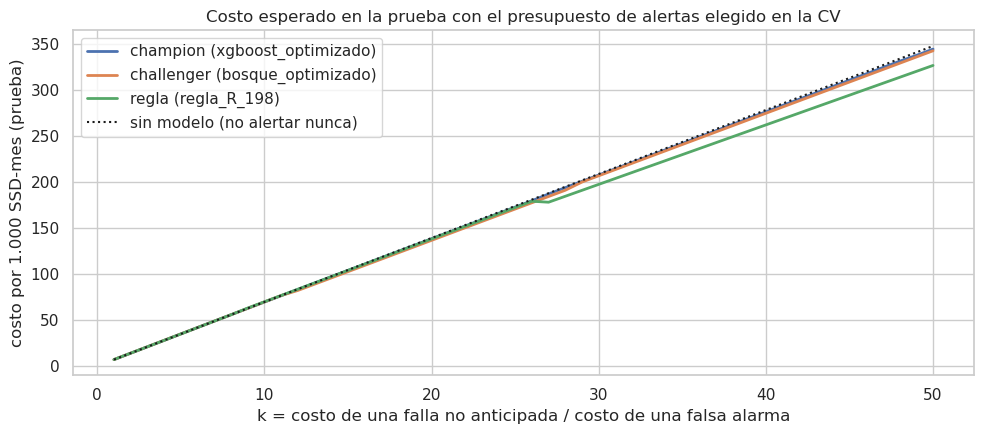

k de equilibrio frente a la regla (menor k desde el que el modelo cuesta menos): {'champion': 9.0, 'challenger': 9.0}


champion                                   challenger                                      regla                                  
           costo alertas_por_1000 alertas aciertos      costo alertas_por_1000 alertas aciertos    costo alertas_por_1000 alertas aciertos
k                                                                                                                                         
1.0000    6.9649           0.0000       0        0     6.9649           0.0000       0        0   6.9649           0.0000       0        0
5.0000   34.8666           0.0422       6        0    34.8596           0.0352       5        0  34.8244           0.0000       0        0
10.0000  69.5503           0.6754      96       10    69.6839           0.0352       5        0  69.8739           1.6181     230       18
20.0000 138.4744           0.9498     135       12   136.7226           0.5276      75       21 138.2563           1.6181     230       18
30.0000 207.8417           1.5126     215       12   206.9975           3.0674     436       23 197.6477           3.9679     564       70
50.0000 344.8669           2.3638     336       16   343.0588           3.0674     436       23 327.0959           3.9679     564       70

In [9]:
COSTOS = {rol: pl.costo_con_presupuesto(prueba["SSD_KEY"], prueba["OBSERVATION_DATE"], prueba["DAYS_TO_FAILURE"],
                                        SCORES[rol], PRESUP_K[rol]) for rol in MODELOS}
fig, ax = plt.subplots(figsize=(10, 4.5))
for rol, c in COSTOS.items():
    ax.plot(c["k"], c["costo"], label=f"{rol} ({ELEGIDOS.get(rol, regla_nombre)})", lw=2)
ax.plot(COSTOS["regla"]["k"], COSTOS["regla"]["costo_sin_modelo"], "k:", label="sin modelo (no alertar nunca)")
ax.set_xlabel("k = costo de una falla no anticipada / costo de una falsa alarma")
ax.set_ylabel("costo por 1.000 SSD-mes (prueba)")
ax.set_title("Costo esperado en la prueba con el presupuesto de alertas elegido en la CV")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "05_costo_vs_k.png", dpi=150); plt.show()

k_eq = {rol: pl.k_equilibrio(COSTOS[rol], COSTOS["regla"]) for rol in ELEGIDOS}
print("k de equilibrio frente a la regla (menor k desde el que el modelo cuesta menos):", k_eq)
tabla_k = pd.concat({rol: c.set_index("k")[["costo", "alertas_por_1000", "alertas", "aciertos"]] for rol, c in COSTOS.items()}, axis=1)
tabla_k.to_csv("../docs/costo_por_k.csv")
tabla_k.loc[[1, 5, 10, 20, 30, 50]]

## 6. Explicabilidad (valores SHAP)

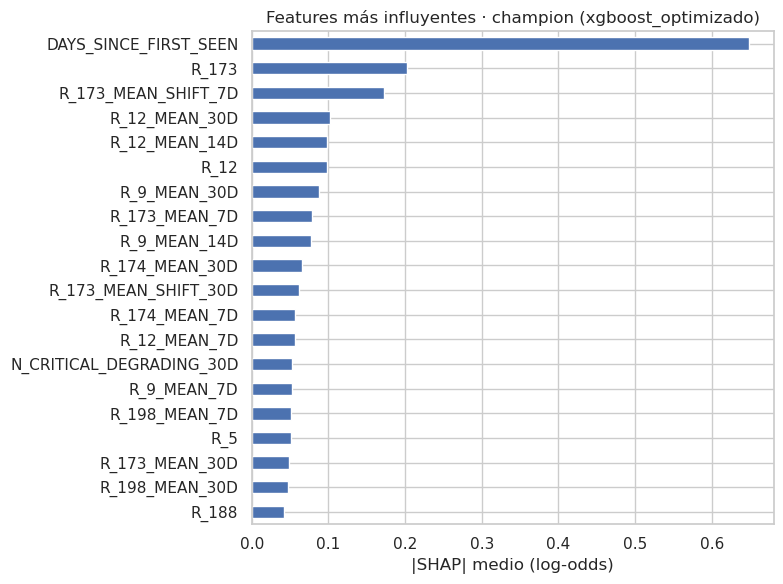

Alerta explicada: disco con score 0.9509 (τ 0.9175), falla 8 días después


,contribucion_log_odds,valor
DAYS_SINCE_FIRST_SEEN,0.6817,566.0000
R_198_MEAN_7D,0.6623,1.0000
N_CRITICAL_DEGRADING_30D,0.4073,NaN
R_198_MEAN_30D,0.3037,1.0000
R_5,0.2220,216.0000
R_198,0.1950,1.0000
R_170,0.1661,216.0000
R_173_MEAN_SHIFT_7D,0.1624,0.0000
R_174_MEAN_30D,0.1313,1.0000
R_180_MEAN_SHIFT_7D,0.1215,-8.5714


In [10]:
# XGBoost calcula valores SHAP exactos de sus árboles (pred_contribs) en GPU; se explica el primer modelo de árboles
import xgboost as xgb
rol_arbol = next((r for r in ("champion", "challenger") if ranking.loc[ELEGIDOS[r], "familia"] in {"xgboost", "bosque"}), None)
if rol_arbol is None:
    print("Ni el champion ni el challenger son de árboles: no se calculan valores SHAP exactos")
else:
    m = MODELOS[rol_arbol]
    nombres = list(COLUMNAS) + [pl.FEATURE_DEGRADACION]
    rng = np.random.default_rng(SEMILLA)
    pos_pos = np.flatnonzero(prueba["TARGET_30D"].to_numpy() == 1)
    muestra = np.concatenate([rng.choice(pos_pos, min(1000, len(pos_pos)), replace=False),
                              rng.choice(len(prueba), 4000, replace=False)])
    Xm = m.named_steps["prep"].transform(X_te.iloc[muestra])
    contrib = m.named_steps["modelo"].get_booster().predict(xgb.DMatrix(Xm), pred_contribs=True)[:, :-1]
    imp = pd.Series(np.abs(contrib).mean(0), index=nombres).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 6))
    imp.head(20)[::-1].plot.barh(ax=ax, color="#4C72B0")
    ax.set_xlabel("|SHAP| medio (log-odds)"); ax.set_title(f"Features más influyentes · {rol_arbol} ({ELEGIDOS[rol_arbol]})")
    fig.tight_layout(); fig.savefig(FIG / "05_shap_importancia.png", dpi=150); plt.show()
    # Un ejemplo: una alerta acertada (disco que falla 7–30 días después, con score ≥ τ)
    s, tau = SCORES[rol_arbol], TAU_TEST[rol_arbol]
    acierto = np.flatnonzero((s >= tau) & prueba["DAYS_TO_FAILURE"].between(7, 30).to_numpy())
    if len(acierto):
        i = acierto[np.argmax(s[acierto])]
        ci = m.named_steps["modelo"].get_booster().predict(
            xgb.DMatrix(m.named_steps["prep"].transform(X_te.iloc[[i]])), pred_contribs=True)[0, :-1]
        ej = pd.Series(ci, index=nombres).sort_values(key=np.abs, ascending=False).head(10)
        print(f"Alerta explicada: disco con score {s[i]:.4f} (τ {tau:.4f}), falla {prueba['DAYS_TO_FAILURE'].iloc[i]:.0f} días después")
        display(pd.DataFrame({"contribucion_log_odds": ej, "valor": X_te.iloc[i].reindex(ej.index)}))
    imp.head(15)

## 7. Registro: corridas finales, Model Registry y `corridas.csv`

In [11]:
VERSIONES = {}
for rol, nombre in ELEGIDOS.items():
    familia = ranking.loc[nombre, "familia"]
    fila = PRUEBA.loc[(rol, "todos")]
    metricas = {"test_pr_auc_evento": fila["pr_auc_evento"], "test_f05_evento": fila["f05_evento"],
                "test_precision_evento": fila["precision_evento"], "test_recall_evento": fila["recall_evento"],
                "test_pr_auc_evento_discos_no_vistos": PRUEBA.loc[(rol, "discos no vistos"), "pr_auc_evento"],
                "tau_operacion": TAU_TEST[rol], "presupuesto_alertas_por_1000": PRESUP_OP[rol],
                "test_alertas_por_1000": fila["alertas_por_1000"], "cv_pr_auc_evento_media": ranking.loc[nombre, "cv_media"],
                "cv_pr_auc_evento_std": ranking.loc[nombre, "cv_std"],
                "segundos_entrenamiento": TIEMPOS[rol]["entrenamiento_s"],
                "inferencia_s_por_millon": TIEMPOS[rol]["inferencia_s_por_millon"],
                "k_equilibrio_vs_regla": k_eq[rol] if k_eq[rol] is not None else np.nan}
    run_id = pl.registrar_corrida(
        nombre=f"final_{rol}_{familia}", fase="final", familia=familia, modelo=MODELOS[rol], seed=SEMILLA,
        metricas=metricas, datos=META_DATOS, X_ejemplo=X_te.head(5),
        params_extra={"frac_sanos_train": FRAC, "entrenamiento": "2018-01-03 a 2019-09-30",
                      "prueba": "2019-11-01 a 2019-11-30", "origen": nombre,
                      **{f"hp_{k}": v for k, v in (PARAMS[rol] or {}).items()}},
        tags_extra={"rol": rol, "corrida_cv": ranking.loc[nombre, "run_id"]})
    version = mlflow.register_model(f"runs:/{run_id}/pipeline", pl.NOMBRE_MODELO_REGISTRO)
    cliente.set_registered_model_alias(pl.NOMBRE_MODELO_REGISTRO, rol, version.version)
    VERSIONES[rol] = {"run_id": run_id, "version": version.version, "test_pr_auc_evento": fila["pr_auc_evento"]}
Path("../docs/registro.json").write_text(json.dumps({"modelo": pl.NOMBRE_MODELO_REGISTRO, **VERSIONES,
                                                     "dataset_sha256": manifiesto["dataset_sha256"]}, indent=2))
VERSIONES

2026/11/17 20:06:08 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/17 20:06:08 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/17 20:06:11 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: 'getpwuid(): uid not found: 4454'


2026/11/17 20:06:11 INFO mlflow.models.model: Found the following environment variables used during model inference: [ANTHROPIC_API_KEY, GEMINI_API_KEY]. Please check if you need to set them when deploying the model. To disable this message, set environment variable `MLFLOW_RECORD_ENV_VARS_IN_MODEL_LOGGING` to `false`.


Registered model 'ssd-failure-modelo' already exists. Creating a new version of this model...


🏃 View run final_champion_xgboost at: http://mlflow:5000/#/experiments/2/runs/5578b7863c0e49cabc664af36dbf4741
🧪 View experiment at: http://mlflow:5000/#/experiments/2


... (6 outputs left out)

2026/11/17 20:06:14 WARNING mlflow.tracking._model_registry.fluent: Run with id 8b38126a0faf43a6a05f92cae860fbd8 has no artifacts at artifact path 'pipeline', registering model based on models:/m-165df71a0dd04b5dbc171f04e509bee6 instead


2026/11/17 20:06:14 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: ssd-failure-modelo, version 4


Created version '4' of model 'ssd-failure-modelo'.


{'champion': {'run_id': '5578b7863c0e49cabc664af36dbf4741',
  'version': '3',
  'test_pr_auc_evento': np.float64(0.007539956157613595)},
 'challenger': {'run_id': '8b38126a0faf43a6a05f92cae860fbd8',
  'version': '4',
  'test_pr_auc_evento': np.float64(0.010159443145869697)}}

In [12]:
corridas = pl.exportar_corridas("../docs/corridas.csv")
print(f"docs/corridas.csv: {len(corridas)} corridas")
print(corridas["tags.fase"].value_counts().to_string())
print(f"Tiempo total del notebook: {(time.time()-T0)/60:.1f} min")

docs/corridas.csv: 112 corridas
tags.fase
tuning       96
candidato     9
final         4
baseline      3
Tiempo total del notebook: 25.2 min


## 8. Conclusiones

| # | Pregunta | Evidencia | Conclusión |
|---|---|---|---|
| 1 | ¿La diferencia entre champion y challenger supera la variación entre pliegues? | CV: XGBoost 0,0192 ± 0,0186, bosque 0,0192 ± 0,0184. Diferencia: 0,00003 | **No.** Es un empate; XGBoost queda como champion solo por la regla fijada de antemano (mayor media) |
| 2 | ¿Qué pasó en la prueba única (nov-2019, 990 eventos)? | PR-AUC por evento: champion 0,0075, challenger 0,0102, regla 0,0102. En su punto de operación: champion 12 aciertos en 141 alertas (F0,5 0,039), challenger 21 en 75 (F0,5 0,081), regla 18 en 230 (F0,5 0,047) | **El challenger rindió mejor que el champion, y la regla R_198 empató con el challenger.** Ninguno anticipa más del 2,2 % de las fallas en su punto de operación |
| 3 | ¿Y al mismo presupuesto de alertas? | Con 5 o más alertas por 1.000 SSD-mes, la regla anticipa 70 fallas con 564 alertas (precisión 0,12); el champion necesita 2.827 alertas para llegar a 47 | Con presupuestos altos la regla es mejor que los dos modelos. Los scores del bosque tienen pocos valores distintos y solo puede emitir 75 o 436 alertas: para él, "mismo presupuesto" es una cota superior, no una igualdad |
| 4 | Métrica de negocio (costo por 1.000 SSD-mes) | k ≤ 8: nadie mejora a no alertar. k de 9 a 11: gana el champion por menos de 0,3 %. k de 12 a 26: gana el challenger (k = 20: 136,7 contra 139,3 sin modelo, 1,9 % de ahorro). k ≥ 27: gana la regla (k = 50: 327,1 contra 348,2, 6,1 % de ahorro; champion 344,9) | El `k_equilibrio = 9` solo indica el primer k en que el modelo cuesta menos que la regla; la ventaja no se mantiene. El ahorro del mejor modelo nunca pasa del 2 % |
| 5 | Costo de cómputo y explicabilidad | Entrenamiento: 400 s (champion) y 367 s (challenger). Inferencia: 4,5 y 4,3 s por millón de filas. Ambos son árboles con valores SHAP exactos; la regla es un umbral sobre un atributo | No hay diferencia práctica entre los dos modelos. La regla es la más barata y la más explicable |

**Decisión (confirmada por el equipo).** Se registra XGBoost optimizado como `@champion` y el bosque optimizado como `@challenger`, por la regla de
selección definida antes de usar la prueba. La evidencia **no** muestra que el champion sea mejor que el challenger ni
que alguno de los dos supere con claridad a la regla R_198: con estos resultados no se justifica reemplazar la regla en
operación, y el modelo registrado queda como punto de partida para el PSet #4, no como una mejora demostrada.

**Limitaciones de esta evaluación.**

- **La prueba se evaluó dos veces.** La primera ejecución de este notebook (commit `a367744`) aplicó en la prueba el τ
  de la CV directamente; al ver que el champion casi no alertaba, se cambió a presupuestos de alertas (sección 2) y se
  volvió a ejecutar (commit `6cb8588`). La PR-AUC por evento no depende del umbral y es idéntica en las dos ejecuciones
  (0,007540 y 0,010159); lo que cambió es el punto de operación: el F0,5 del champion pasó de 0,014 a 0,039 y el del
  challenger de 0,084 a 0,081. Por eso `docs/corridas.csv` tiene cuatro corridas `fase=final`; las dos primeras llevan
  el tag `estado=reemplazada` (`scripts/marcar_finales_reemplazadas.py`). El método de umbral se eligió, entonces,
  conociendo un resultado de la prueba, y los números de operación y de costo son optimistas en esa medida.
- **No hay discos nuevos con falla en la prueba** (0 eventos entre los discos no vistos): no se puede medir cómo
  generaliza el modelo a discos que no estaban en entrenamiento.
- **Un solo mes de prueba.** La CV mostró desviaciones entre pliegues del mismo tamaño que las medias; un mes distinto
  podría ordenar los tres de otra forma.

- **46 de las 112 corridas tienen el commit marcado `-dirty`**: el candidato TabPFN, 14 del tuning del bosque y 31 del
  tuning de la MLP (commits `32225bb` y `a367744`). Lo único sin commit en ese momento eran las salidas del notebook 03
  ejecutado; el código era el del commit registrado. Desde `278a3fa`, `commit_git` no cuenta las salidas de notebooks
  ni `docs/`, y las corridas siguientes quedaron limpias. Volver a correrlas solo cambiaría la etiqueta.
- **Configuraciones completas en el tuning:** se evaluaron 30 por familia, pero por la poda solo 18 (bosque), 15 (MLP)
  y 19 (XGBoost) completaron la CV (ver notebook 04).